In [1]:
import pickle as pk
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns          # if ImportError: pip install seaborn  (then restart the kernel)
from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")

FIG_DIR = Path("figures")          # figures for the progress report get saved here
FIG_DIR.mkdir(exist_ok=True)

# Week 2 Helper Notebook
This exploration should produce AT LEAST three figures , which you should include in the progress report and make look nice using seaborn (feel free to use AI to help with plotting). 
1. {AUROC/AUPRC} by held-out hospital, with internal {AUROC/AUPRC} as a dashed reference.
2. Generalization gap by each heldout hospital.
3. At least one exploratory diagnostic, such as generalization gap vs missingness shift or feature-distribution shift.

General guiding goal: 
* Can we establish that some hospitals generalize much worse than others? Can we trace that failure to particular features / can information available across the training hospitals tell us ahead of time which features are risky?

## Step 1: Load eICU data

In [2]:
feature_sets = pk.load(open('/Users/gabrielarm300/cs197_fall2026/data/feature_names.pkl', 'rb'))
patient_agg = pd.read_parquet('/Users/gabrielarm300/cs197_fall2026/data/clean_dataset.parquet')

print("Dataset shape:", patient_agg.shape)
patient_agg.head()

Dataset shape: (135778, 2167)


,patienthealthsystemstayid,gender,age,ethnicity,hospitalid,hospitaldischargeyear,mortality_at48h,hospital_numbedscategory,hospital_region,"admissiondx_ARDS-adult respiratory distress syndrome, non-cardiogenic pulmonary edema",admissiondx_Abdomen only trauma,admissiondx_Abdomen/extremity trauma,admissiondx_Abdomen/face trauma,admissiondx_Abdomen/multiple trauma,admissiondx_Abdomen/pelvis trauma,admissiondx_Abdomen/spinal trauma,admissiondx_Ablation or mapping of cardiac conduction pathway,"admissiondx_Abscess, neurologic","admissiondx_Abscess/infection-cranial, surgery for",admissiondx_Acid-base/electrolyte disturbance,admissiondx_Addisons disease,admissiondx_Adrenal neoplasm (including pheochromocytoma),admissiondx_Adrenalectomy,admissiondx_Alcohol withdrawal,admissiondx_Amputation (non-traumatic),admissiondx_Amyotrophic lateral sclerosis,admissiondx_Anaphylaxis,"admissiondx_Anastomosis, vascular",admissiondx_Anemia,"admissiondx_Aneurysm repair, ventricular","admissiondx_Aneurysm, abdominal aortic","admissiondx_Aneurysm, abdominal aortic; with dissection","admissiondx_Aneurysm, abdominal aortic; with rupture","admissiondx_Aneurysm, dissecting aortic","admissiondx_Aneurysm, thoracic aortic","admissiondx_Aneurysm, thoracic aortic; with dissection","admissiondx_Aneurysm, thoracic aortic; with rupture","admissiondx_Aneurysm/pseudoaneurysm, other","admissiondx_Aneurysms, repair of other (except ventricular)","admissiondx_Angina, stable (asymp or stable pattern of symptoms w/meds)","admissiondx_Angina, unstable (angina interferes w/quality of life or meds are tolerated poorly)",admissiondx_Aortic and Mitral valve replacement,admissiondx_Aortic valve replacement (isolated),"admissiondx_Apnea, sleep","admissiondx_Apnea-sleep; surgery for (i.e., UPPP - uvulopalatopharyngoplasty)",admissiondx_Appendectomy,"admissiondx_Arrest, respiratory (without cardiac arrest)","admissiondx_Arteriovenous malformation, surgery for","admissiondx_Arthritis, rheumatoid","admissiondx_Arthritis, septic",...,calcium,cd 4,chloride,cortisol,creatinine,direct bilirubin,eos,ethanol,fibrinogen,folate,free T4,glucose,glucose CSF,haptoglobin,ionized calcium,lactate,lipase,lymphs,magnesium,monos,myoglobin,pH,paCO2,paO2,phosphate,platelets x 1000,polys,potassium,prealbumin,prolactin,protein CSF,protein C,protein S,reticulocyte count,salicylate,serum ketones,serum osmolality,sodium,total bilirubin,total cholesterol,total protein,transferrin,triglycerides,troponin I,troponin T,uric acid,urinary creatinine,urinary osmolality,urinary sodium,urinary specific gravity
0,128919,Female,70,Caucasian,59,2015,1,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,9.000000,NaN,101.500000,NaN,2.125000,NaN,0.5,NaN,NaN,NaN,NaN,113.0,NaN,NaN,NaN,NaN,NaN,12.500000,NaN,16.500000,NaN,NaN,NaN,NaN,NaN,211.000000,70.5,4.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139.000000,3.35,NaN,7.10,NaN,NaN,NaN,NaN,8.1,NaN,NaN,NaN,NaN
1,128927,Female,52,Caucasian,60,2015,0,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,8.100000,NaN,107.750000,NaN,0.700000,NaN,3.0,234.0,NaN,NaN,NaN,74.5,NaN,NaN,NaN,NaN,NaN,45.000000,1.90,7.000000,NaN,NaN,NaN,NaN,NaN,273.000000,45.0,3.750000,NaN,NaN,NaN,NaN,NaN,NaN,2.3,NaN,NaN,144.500000,0.40,NaN,7.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,128941,Male,68,Caucasian,73,2015,0,>= 500,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,9.200000,NaN,103.500000,NaN,2.725000,0.1,0.5,NaN,NaN,NaN,NaN,151.5,NaN,NaN,NaN,1.666667,NaN,3.500000,1.20,4.500000,NaN,NaN,NaN,NaN,NaN,265.500000,91.5,4.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,134.500000,0.40,NaN,7.45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.018
3,128943,Male,71,Caucasian,67,2015,0,None,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,9.000000,NaN,98.000000,NaN,0.865000,NaN,0.0,NaN,NaN,NaN,NaN,153.0,NaN,NaN,NaN,0.800000,NaN,3.000000,NaN,4.500000,NaN,

In [3]:
# This distinction of numerical (continuous), binary, and categorical
# columns may be useful throughout the project.
all_num_cols = (
    feature_sets['labs'].tolist()
    + feature_sets['vitals'].tolist()
    + ['age', 'admissionheight', 'admissionweight']
)

all_bin_cols = (
    feature_sets['icd10_before24h'].tolist()
    + feature_sets['admissiondx'].tolist()
)

all_cat_cols = [
    # 'hospital_region',
    'ethnicity',
    'gender',
    'hospital_numbedscategory',
    'hospitaldischargeyear',
    # 'hospitalid'
]

In [4]:
# For privacy, eICU records patients older than 89 using the string "> 89".
if 'age' in patient_agg.columns:
    patient_agg.loc[patient_agg.age == '> 89', 'age'] = 90
    patient_agg['age'] = patient_agg['age'].astype(float)

## Step 1: Investigate possible prediction outcomes Y

In [5]:
# Y must occur AFTER the time window used to construct X. Why?
#   X is built from the first 24 hours. If Y happened inside (or before) that window, X could "see" the
#   outcome (e.g. a test ordered *because* the patient was already crashing) and the model would look
#   great for the wrong reason (label leakage). mortality_at48h is measured after the 24h feature window.
#   (Double check in the Week 1 notebook that this is how it was defined.)

#OUTCOME_COL = 'mortality_at48h'
OUTCOME_COL = 'label_J96.00'

# a missing outcome is treated as "did not happen" (same assumption as Week 1)
patient_agg[OUTCOME_COL] = patient_agg[OUTCOME_COL].fillna(0).astype(int)

print(f"Prevalence: {patient_agg[OUTCOME_COL].mean():.2%}")
patient_agg[OUTCOME_COL].value_counts(dropna=False)

Prevalence: 9.35%


label_J96.00
0    123085
1     12693
Name: count, dtype: int64

In [6]:
prev = patient_agg[feature_sets['icd10_after24h'].tolist()].fillna(0).mean().sort_values(ascending=False)
print(prev.head(15))

label_J96.00    0.093483
label_I10       0.070623
label_N17.9     0.065511
label_J18.9     0.053440
label_I48.0     0.048741
label_A41.9     0.037289
label_I50.9     0.037024
label_R41.82    0.034056
label_R73.9     0.031146
label_I95.9     0.030550
label_J44.9     0.027884
label_J96.91    0.026359
label_R65.21    0.026337
label_K92.2     0.025394
label_N18.9     0.021079
dtype: float64


## Step 2: Choose X
Think: What are variables that are realistic and useful in predicting Y? For example, we probably wouldn't use region of hospital to predict mortality, but we might use lab measurements.

In [7]:
# Realistic predictors available inside the first 24h:
#   numeric:     labs, vitals, age, height, weight
#   binary:      diagnoses before 24h, admission diagnoses
#   categorical: gender, ethnicity   (ethnicity is a sensitive covariate -- drop it if you'd rather not use it)
#
# Deliberately NOT used:
#   hospitalid -> an identifier, and it is what we split on
#   hospital_region / hospital_numbedscategory / hospitaldischargeyear -> descriptions of the hospital,
#     not of the patient. A model using them can just memorise hospitals, which defeats the generalization question.
#X_num = [c for c in all_num_cols if c in patient_agg.columns]
#X_bin = [c for c in all_bin_cols if c in patient_agg.columns]
#X_cat = [c for c in ['gender', 'ethnicity'] if c in patient_agg.columns]

#X_cols = X_num + X_bin + X_cat
#assert 'hospitalid' not in X_cols
#assert OUTCOME_COL not in X_cols
#print(f"{len(X_num)} numeric, {len(X_bin)} binary, {len(X_cat)} categorical features")




X_num = [c for c in all_num_cols if c in patient_agg.columns]
X_bin = [c for c in all_bin_cols if c in patient_agg.columns]
X_cat = [c for c in ['gender', 'ethnicity'] if c in patient_agg.columns]

# drop earlier codes from the same ICD category as the outcome (e.g. all J96.* when predicting label_J96.00)
outcome_prefix = OUTCOME_COL.replace('label_', '').split('.')[0]
dropped = [c for c in X_bin if c.startswith(outcome_prefix)]
X_bin = [c for c in X_bin if not c.startswith(outcome_prefix)]
print("dropped from X_bin:", dropped)

X_cols = X_num + X_bin + X_cat
assert 'hospitalid' not in X_cols
assert OUTCOME_COL not in X_cols
print(f"{len(X_num)} numeric, {len(X_bin)} binary, {len(X_cat)} categorical features")

dropped from X_bin: ['J96.0', 'J96.00', 'J96.10', 'J96.20', 'J96.91', 'J96.92']
213 numeric, 1161 binary, 2 categorical features


In [8]:
print([c for c in X_bin if 'J96' in c])

[]


## Step 3: Understand different hospital statistics

In [9]:
# Sample size, outcome prevalence, and a couple of other statistics for every hospital
hosp_stats = (
    patient_agg.groupby('hospitalid')
    .agg(n_patients=(OUTCOME_COL, 'size'),
         n_pos=(OUTCOME_COL, 'sum'),
         prevalence=(OUTCOME_COL, 'mean'),
         mean_age=('age', 'mean'))
)
hosp_stats['n_neg'] = hosp_stats['n_patients'] - hosp_stats['n_pos']

# average fraction of numeric features that are missing at each hospital
hosp_stats['avg_frac_missing'] = (
    patient_agg[X_num].isna().groupby(patient_agg['hospitalid']).mean().mean(axis=1)
)

# hospital descriptors (constant within a hospital)
hosp_attr_cols = [c for c in ['hospital_region', 'hospital_numbedscategory'] if c in patient_agg.columns]
if hosp_attr_cols:
    hosp_stats = hosp_stats.join(patient_agg.groupby('hospitalid')[hosp_attr_cols].first())

print(f"{len(hosp_stats)} hospitals")
display(hosp_stats.describe().T)
hosp_stats.sort_values('prevalence').head(10)

208 hospitals


,count,mean,std,min,25%,50%,75%,max
n_patients,208.0,652.778846,783.699864,3.000000,151.500000,388.500000,866.250000,4591.000000
n_pos,208.0,61.024038,119.138552,0.000000,4.750000,18.000000,70.500000,1211.000000
prevalence,208.0,0.083584,0.079066,0.000000,0.022278,0.065366,0.128053,0.367750
mean_age,208.0,63.068303,5.205639,29.289474,61.039081,63.338278,65.385996,77.666667
n_neg,208.0,591.754808,711.926211,3.000000,143.750000,336.500000,751.250000,4332.000000
avg_frac_missing,208.0,0.761977,0.043868,0.699343,0.737780,0.752806,0.770929,0.981221


,n_patients,n_pos,prevalence,mean_age,n_neg,avg_frac_missing,hospital_region,hospital_numbedscategory
hospitalid,,,,,,,,
267,153,0,0.0,68.725490,153,0.769800,Midwest,<100
263,39,0,0.0,65.051282,39,0.782954,None,None
136,3,0,0.0,46.333333,3,0.981221,South,<100
342,157,0,0.0,67.866242,157,0.783170,Midwest,<100
351,20,0,0.0,61.000000,20,0.881925,None,None
96,11,0,0.0,46.090909,11,0.758429,None,None
356,52,0,0.0,72.000000,52,0.745305,Midwest,<100
94,5,0,0.0,65.400000,5,0.711737,Midwest,100 - 249
363,49,0,0.0,62.346939,49,0.746479,Midwest,<100


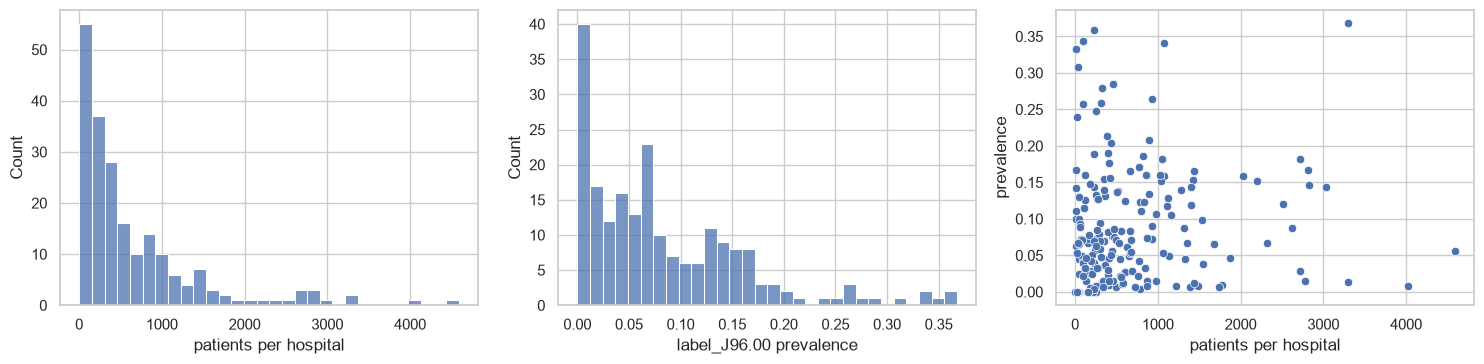

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(hosp_stats['n_patients'], bins=30, ax=axes[0]);  axes[0].set_xlabel('patients per hospital')
sns.histplot(hosp_stats['prevalence'], bins=30, ax=axes[1]);  axes[1].set_xlabel(f'{OUTCOME_COL} prevalence')
sns.scatterplot(data=hosp_stats, x='n_patients', y='prevalence', ax=axes[2])
axes[2].set_xlabel('patients per hospital'); axes[2].set_ylabel('prevalence')
plt.tight_layout()
plt.show()

#Left: most hospitals are small, and a few are huge.
#Middle: most hospitals have about 3 to 5% of patients die.
#Right: small hospitals are all over the place (0% to 20%), and big hospitals settle around 3 to 6%.

**What does it mean if a hospital has a really low Y prevalence, or a really small sample size? Should we remove them?**

The thing about small hospitals is that their data changes dramatically almost by luck. A hospital with 5 peolple and 0 deaths tells you nothing. Meanwhile, if one of them dies that would be a massive percentage.
For mortality, nearly every hospital was around 3 to 5%. A wide spread is a good sign for finding a generalization gap.
The zero-case hospitals look meaningful. Several are tiny (3, 5, or 11 patients), so zero is just small numbers. 
There’s a pattern. The zero-case hospitals with a known region and size are mostly small (under 100 beds) and in the Midwest.

## Step 4: Explore / pick possible hospital train/heldout splits

In [11]:
# Pick some K, maybe 10. Then try splitting by hospital region, number of beds, for K hospitals in the training data. 
# Suggested requirements:
#
# n_train_patients > 10,000
# 5 <= n_heldout_hospitals < 15
#
# PLUS enough positive and negative outcomes in every held-out hospital.
K_HELDOUT    = 10
MIN_HELD_N   = 300     # min patients in a held-out hospital
MIN_HELD_POS = 15      # min positives AND min negatives in a held-out hospital
# (if you get too few eligible hospitals, lower these)

eligible = hosp_stats[(hosp_stats.n_patients >= MIN_HELD_N)
                      & (hosp_stats.n_pos >= MIN_HELD_POS)
                      & (hosp_stats.n_neg >= MIN_HELD_POS)]
print(f"{len(eligible)} of {len(hosp_stats)} hospitals are eligible to be held out")
assert len(eligible) >= K_HELDOUT, "Not enough eligible hospitals: lower MIN_HELD_N / MIN_HELD_POS"

# candidate splits: a few random ones, plus "hold out hospitals from one region"
eligible_ids = eligible.index.to_numpy()
candidates = {}
for s in range(5):
    candidates[f'random_{s}'] = np.random.default_rng(s).choice(eligible_ids, size=K_HELDOUT, replace=False)

if 'hospital_region' in eligible.columns:
    for region, grp in eligible.groupby('hospital_region'):
        ids = grp.index.to_numpy()
        if len(ids) >= 5:
            candidates[f'region={region}'] = ids if len(ids) < 15 else np.random.default_rng(0).choice(ids, 14, replace=False)

def summarize_split(ids):
    ids = list(ids)
    n_held = hosp_stats.loc[ids, 'n_patients'].sum()
    pos_held = hosp_stats.loc[ids, 'n_pos'].sum()
    n_total, pos_total = hosp_stats['n_patients'].sum(), hosp_stats['n_pos'].sum()
    n_train = n_total - n_held
    return dict(n_heldout_hosp=len(ids), n_train=int(n_train), n_heldout=int(n_held),
                train_prev=(pos_total - pos_held) / n_train, heldout_prev=pos_held / n_held,
                min_pos_in_heldout_hosp=int(hosp_stats.loc[ids, 'n_pos'].min()))

split_table = pd.DataFrame({name: summarize_split(ids) for name, ids in candidates.items()}).T
split_table['valid'] = (split_table.n_train > 10_000) & split_table.n_heldout_hosp.between(5, 14)
split_table

96 of 208 hospitals are eligible to be held out


,n_heldout_hosp,n_train,n_heldout,train_prev,heldout_prev,min_pos_in_heldout_hosp,valid
random_0,10.0,125137.0,10641.0,0.096095,0.062776,16.0,True
random_1,10.0,123420.0,12358.0,0.093016,0.098155,16.0,True
random_2,10.0,124267.0,11511.0,0.093846,0.089567,29.0,True
random_3,10.0,123785.0,11993.0,0.092208,0.106646,16.0,True
random_4,10.0,125806.0,9972.0,0.094463,0.081127,17.0,True
region=Midwest,14.0,116466.0,19312.0,0.099042,0.059963,17.0,True
region=Northeast,8.0,127352.0,8426.0,0.085605,0.212556,29.0,True
region=South,14.0,117638.0,18140.0,0.088679,0.124642,15.0,True
region=West,14.0,125436.0,10342.0,0.088683,0.151711,21.0,True


In [12]:
## Create train / heldout data split
#  DOUBLE check there is no overlap of heldout data with train data!!
CHOSEN_SPLIT = 'random_0'     # <- change to try other splits (e.g. 'region=South')
assert split_table.loc[CHOSEN_SPLIT, 'valid'], "This split does not meet the suggested requirements"

heldout_hospitals = list(candidates[CHOSEN_SPLIT])
is_heldout = patient_agg['hospitalid'].isin(heldout_hospitals)

train_df   = patient_agg[~is_heldout].copy()    #all patients in the training hospitals
heldout_df = patient_agg[is_heldout].copy()     #all patients in the held-out hospitals

# --- sanity checks: no hospital (hence no patient) appears on both sides, and nothing was lost
assert set(train_df['hospitalid']).isdisjoint(set(heldout_df['hospitalid']))
assert len(train_df) + len(heldout_df) == len(patient_agg)
print(f"train: {len(train_df):,} patients in {train_df.hospitalid.nunique()} hospitals | "
      f"held-out: {len(heldout_df):,} patients in {heldout_df.hospitalid.nunique()} hospitals")

# Internal validation set: a random 20% of the TRAINING hospitals' patients (same hospitals as training).
# We tune the model on it, and it is our "internal performance" reference.
train_inner, val_inner = train_test_split(
    train_df, test_size=0.2, random_state=SEED, stratify=train_df[OUTCOME_COL]
)
train_inner, val_inner = train_inner.copy(), val_inner.copy()
print(f"inner train: {len(train_inner):,} | internal validation: {len(val_inner):,}")

train: 125,137 patients in 198 hospitals | held-out: 10,641 patients in 10 hospitals
inner train: 100,109 | internal validation: 25,028


## DETOUR: Handling missing data 

You may have noticed that variables are often missing in our dataset. For example, age is missing for 0.0346% of all patients, the lab measurement of ANF/ANA is missing for 99.9%, and height is missing for 2%.

Categorical variables can be missing too. For example, if a patient's gender was not recorded.

However, missing values are easier to handle in categorical variables than in continuous ones, because when we one-hot encode the variable, we can simply add one more column for "missing". For example:

|Patient| Recorded gender  | female | male | missing |
|:--|------------------|:------:|:----:|:-------:|
|A| female           |   1    |  0   |    0    |
|B| male             |   0    |  1   |    0    |
|C| *(not recorded)* |   0    |  0   |    1    |

The model treats "missing" like any other category, so it can learn how common it is and even generate it in synthetic data.

The challenge with continuous variables is that we need a numerical input to our model, because NaNs are not valid inputs (a single NaN in a row makes the loss NaN, and then all the weights become NaN too).

**Your goal is to briefly explore and pick one way of handling missingness for continuous variables.** Note, how you define missing values will change how you choose to model continuous variables. Some suggestions are:


1. **Drop the patients** that contain ANY missing value. Simple, but you may throw away a lot of data. 
2. **Fill with a constant**, such as the mean or median (computed on the training set only!). Easy, but many patients now share exactly the same value and the data can lose some predictive power. Use `sklearn.impute.SimpleImputer`. 
4. **Fill with the median and add a "was it missing?" binary variable**, the same trick as for categorical variables. Again use median of training data.
    - Note if you do this: You will need to add on these extra "was missing" variable (# new binary cols = # continuous variables) to the list above of `bin_cols`
6. **Predict the missing value from the other columns** on the training data only (for example a regression, k-nearest neighbors, or a MICE-style imputer such as scikit-learn's `IterativeImputer`). If you use imputation, you are free to use AI to help you impute the dataframe above !!
7. **Multiple imputation.** Fill the gaps several different (random) ways to get several complete datasets, then use a different one in each epoch. If you use imputation, you are free to use AI to help you impute the dataframe above !!


For example, say you build some Imputer class. You would want to do 
```
imp = Imputer()
imp.fit(train_df numerical data)

imputed train = imp.transform(train_df numerical data)
imputed val = imp.transform(val_df numerical data)

```

**What this notebook does:** option 4 (median + "was it missing?" indicator), fit on the inner training split only. Why option 4? In ICU data a lab is often missing *because the clinician didn't think it was needed*, so "missing" itself carries signal, and the indicator lets the model use it. It is also cheap and easy to explain. (Compare with option 2 as an ablation if you have time.)

In [13]:
# first for categorical data, just fill in the missing values with the string Missing. 
# -Ask yourself, why? What might this information preserve? 
#   Answer: "not recorded" is often informative (e.g. patients admitted in a hurry, or transferred, have
#   less complete demographics). A "Missing" category keeps that signal instead of throwing the patient away
#   or guessing a value. It is a constant, not a statistic learned from data, so it cannot leak across splits.
for d in (train_inner, val_inner, heldout_df):
    d[X_cat] = d[X_cat].astype(object).fillna('Missing')

train_inner[X_cat].describe()

,gender,ethnicity
count,100109,100109
unique,5,7
top,Male,Caucasian
freq,53760,76173


In [14]:
# handle numerical missing values, then join together
#
# (1) Drop numeric features that are almost always missing in the TRAINING split (e.g. ANF/ANA is 99.9% missing):
#     with so little data a median fill means "everyone looks the same" and an indicator is nearly constant.
MAX_MISSING = 0.95
miss_train = train_inner[X_num].isna().mean()
X_num_kept = miss_train[miss_train <= MAX_MISSING].index.tolist()
print(f"Dropping {len(X_num) - len(X_num_kept)} of {len(X_num)} numeric columns that are >{MAX_MISSING:.0%} missing in training")

# (2) median fill + "was missing" indicator. FIT ON THE TRAINING SPLIT ONLY.
num_imputer = SimpleImputer(strategy='median', add_indicator=True)
num_imputer.fit(train_inner[X_num_kept])
imp_names = num_imputer.get_feature_names_out().tolist()    # original names, then 'missingindicator_<name>'

def impute_numeric(d):
    return pd.DataFrame(num_imputer.transform(d[X_num_kept]), columns=imp_names, index=d.index)

# (3) join numeric + binary + categorical
def build_frame(d):
    return pd.concat([impute_numeric(d), d[X_bin].fillna(0), d[X_cat]], axis=1)

Xtr, Xva, Xho = build_frame(train_inner), build_frame(val_inner), build_frame(heldout_df)
ytr, yva, yho = train_inner[OUTCOME_COL], val_inner[OUTCOME_COL], heldout_df[OUTCOME_COL]
print(Xtr.shape, Xva.shape, Xho.shape)

Dropping 109 of 213 numeric columns that are >95% missing in training
(100109, 1371) (25028, 1371) (10641, 1371)


In [15]:
# Make sure that imputer is learned / fit ONLY over your final frozen train split,
# and then applied to the test set (ie. if computing a mean, compute the mean of the training set)
# -> num_imputer.fit(...) above only ever saw train_inner. val_inner and heldout_df only went through .transform().
for name, d in [('train', Xtr), ('val', Xva), ('heldout', Xho)]:
    assert d.isnull().sum().sum() == 0, f"{name}: Data should not have missing values after imputation"
print("No missing values left in train / val / heldout.")

No missing values left in train / val / heldout.


## Step 5: Build a simple baseline model 

In [16]:
# First, preprocess the data, ie. imputation (done above), one hot encoding, scaling. Use sklearn.
ind_cols    = [c for c in imp_names if c.startswith('missingindicator_')]   # 0/1 "was missing" flags
num_scaled  = [c for c in imp_names if not c.startswith('missingindicator_')]

prep = ColumnTransformer([
    ('num',  StandardScaler(), num_scaled),                                    # continuous -> mean 0, sd 1
    ('cat',  OneHotEncoder(handle_unknown='ignore', sparse_output=False), X_cat),   # words -> 0/1 columns
    ('pass', 'passthrough', ind_cols + X_bin),                                 # already 0/1
], remainder='drop')

In [17]:
# Define the model, XGBoost or Logistic Regression. Use sklearn.
# Logistic regression. The only knob is the regularization strength C (smaller C = stronger shrinkage),
# which we tune on the INTERNAL validation set (never on the held-out hospitals).
fitted = {}
for C in [0.001, 0.01, 0.1, 1.0]:
    m = Pipeline([('prep', clone(prep)), ('lr', LogisticRegression(C=C, max_iter=2000))])
    m.fit(Xtr, ytr)                                          # Learn on the training data
    fitted[C] = m
    print(f"C={C:<6} internal-val AUPRC = {average_precision_score(yva, m.predict_proba(Xva)[:, 1]):.4f}")

best_C = max(fitted, key=lambda C: average_precision_score(yva, fitted[C].predict_proba(Xva)[:, 1]))
model = fitted[best_C]
print("Chosen C:", best_C)

C=0.001  internal-val AUPRC = 0.4297
C=0.01   internal-val AUPRC = 0.4658
C=0.1    internal-val AUPRC = 0.4797
C=1.0    internal-val AUPRC = 0.4790
Chosen C: 0.1


In [18]:
#Small C (like 0.001): a strict teacher. The weights are squeezed close to zero, so the model stays simple and only keeps the strongest patterns.
#Large C (like 1.0): a relaxed teacher. The weights can get big, so the model can chase small details.

## Step 6: Evaluate model performance internally
Typical metrics for binary outcomes are AUROC, AUPRC, brier score, and accuracy (but ask yourself -- what do each metrics mean? what metrics do we care about most? what happens if Y is very skewed? is there one metric we should prioritize?) Note that for brier, lower brier is better. 

In [19]:
def get_auroc(model, Xdata, Ydata):
    return roc_auc_score(Ydata, model.predict_proba(Xdata)[:, 1])

def get_auprc(model, Xdata, Ydata):
    return average_precision_score(Ydata, model.predict_proba(Xdata)[:, 1])

def get_brier(model, Xdata, Ydata):
    return brier_score_loss(Ydata, model.predict_proba(Xdata)[:, 1])

def score_all(y, p):
    # all metrics from labels y and predicted probabilities p (needs both classes in y)
    return dict(n=len(y), n_pos=int(np.sum(y)), prevalence=float(np.mean(y)),
                auroc=roc_auc_score(y, p), auprc=average_precision_score(y, p), brier=brier_score_loss(y, p))

In [20]:
# calculate average, or perhospital internal model performance on the training data . basically you want a validation
# metric scores that are NOT the heldout hospitals. 
p_val = model.predict_proba(Xva)[:, 1]
internal = score_all(yva.to_numpy(), p_val)
int_auroc, int_auprc, int_brier = internal['auroc'], internal['auprc'], internal['brier']
print(f"INTERNAL (pooled validation): AUROC={int_auroc:.3f}  AUPRC={int_auprc:.3f}  Brier={int_brier:.4f}  "
      f"(prevalence={internal['prevalence']:.2%})")

# per training hospital (only hospitals with enough validation positives/negatives to score)
rows = []
for h in val_inner['hospitalid'].unique():
    m = (val_inner['hospitalid'] == h).to_numpy()
    y_h = yva.to_numpy()[m]
    if y_h.sum() >= 5 and (len(y_h) - y_h.sum()) >= 5:
        rows.append(dict(hospitalid=h, **score_all(y_h, p_val[m])))
internal_by_hosp = pd.DataFrame(rows)
print(f"Per-hospital internal metrics for {len(internal_by_hosp)} training hospitals "
      f"(mean AUROC={internal_by_hosp.auroc.mean():.3f}, mean AUPRC={internal_by_hosp.auprc.mean():.3f})")
internal_by_hosp.describe().T[['count', 'mean', 'std', 'min', 'max']]

INTERNAL (pooled validation): AUROC=0.876  AUPRC=0.480  Brier=0.0648  (prevalence=9.61%)
Per-hospital internal metrics for 86 training hospitals (mean AUROC=0.837, mean AUPRC=0.476)


,count,mean,std,min,max
hospitalid,86.0,290.093023,123.521051,63.000000,459.000000
n,86.0,216.976744,179.003909,17.000000,958.000000
n_pos,86.0,26.267442,29.208953,5.000000,206.000000
prevalence,86.0,0.139576,0.082996,0.011094,0.452381
auroc,86.0,0.837363,0.081475,0.469841,0.970833
auprc,86.0,0.475541,0.199278,0.051247,0.925000
brier,86.0,0.092074,0.045460,0.011697,0.232867


**Which metric matters most?**
AUROC is better. Because our hospitals fluctuate so much in terms of their outcomes (from 1% to 45% for label_J96.00, an acute respiratory failure diagnosis recorded after the first 24 hours). AUPRC focuses more on finding rare cases (rather than gaps) and Brier depends on how common the outcome is.

## Step 7: Evaluate external model performance and also generalization gap 
NOTE: When developing our "method", we won't assume we know these heldout hospital data.

In [28]:
# calculate heldout hospital performance. plot the worst. 
p_ho = model.predict_proba(Xho)[:, 1]
y_ho = yho.to_numpy()

rows = []
for h in sorted(heldout_df['hospitalid'].unique()):
    m = (heldout_df['hospitalid'] == h).to_numpy()
    rows.append(dict(hospitalid=h, hospital=str(h), **score_all(y_ho[m], p_ho[m])))
ext = pd.DataFrame(rows)

# generalization gap = internal - external  (for Brier, lower is better, so external - internal)
ext['gap_auroc'] = int_auroc - ext['auroc']
ext['gap_auprc'] = int_auprc - ext['auprc']
ext['gap_brier'] = ext['brier'] - int_brier
ext['auprc_over_prev'] = ext['auprc'] / ext['prevalence']     # AUPRC relative to chance, easier to compare across prevalences

ext.sort_values('gap_auroc', ascending=False).round(3)

,hospitalid,hospital,n,n_pos,prevalence,auroc,auprc,brier,gap_auroc,gap_auprc,gap_brier,auprc_over_prev
6,264,264,4025,35,0.009,0.781,0.050,0.012,0.095,0.430,-0.053,5.734
9,404,404,305,18,0.059,0.818,0.204,0.056,0.058,0.275,-0.009,3.463
1,71,71,601,16,0.027,0.820,0.125,0.027,0.057,0.354,-0.037,4.708
7,336,336,762,17,0.022,0.843,0.080,0.023,0.034,0.400,-0.042,3.590
0,66,66,630,39,0.062,0.850,0.328,0.050,0.026,0.151,-0.015,5.305
4,176,176,2030,322,0.159,0.877,0.565,0.094,-0.001,-0.086,0.030,3.564
2,92,92,441,34,0.077,0.882,0.376,0.060,-0.005,0.104,-0.005,4.875
3,152,152,834,103,0.124,0.884,0.565,0.074,-0.008,-0.085,0.010,4.573
5,184,184,662,35,0.053,0.896,0.301,0.042,-0.020,0.179,-0.022,5.684
8,397,397,351,49,0.140,0.899,0.577,0.087,-0.023,-0.098,0.022,4.136


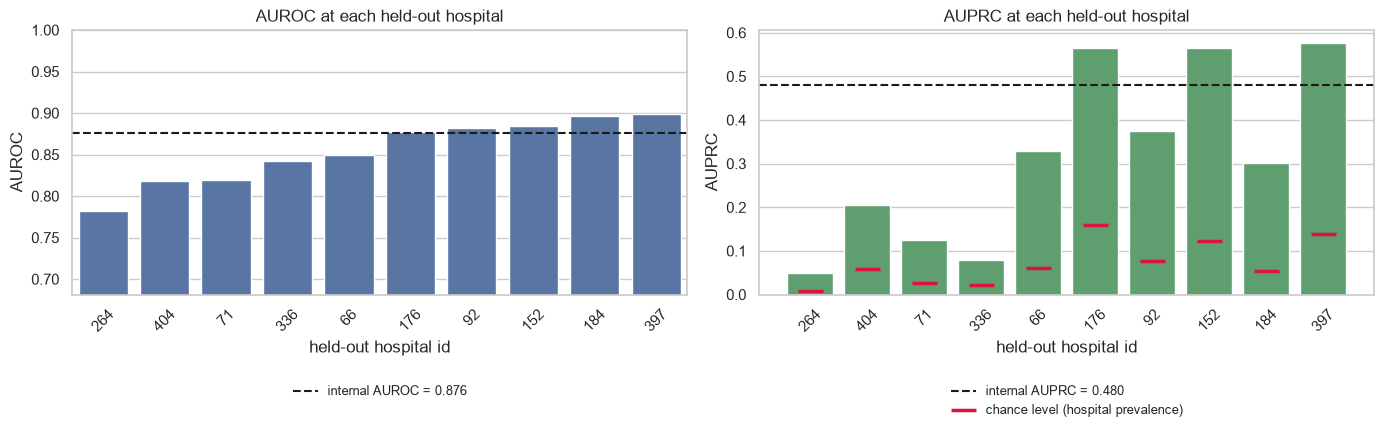

In [29]:
# FIGURE 1: AUROC and AUPRC at each held-out hospital, with the internal score as a dashed reference
order = ext.sort_values('auroc')['hospital'].tolist()                 # worst -> best AUROC
e = ext.set_index('hospital').loc[order].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.barplot(data=e, x='hospital', y='auroc', order=order, color='#4C72B0', ax=axes[0])
axes[0].axhline(int_auroc, ls='--', color='k', label=f'internal AUROC = {int_auroc:.3f}')
axes[0].set_ylim(max(0, e.auroc.min() - 0.1), 1)
axes[0].set_title('AUROC at each held-out hospital'); axes[0].set_ylabel('AUROC'); axes[0].set_xlabel('held-out hospital id')

sns.barplot(data=e, x='hospital', y='auprc', order=order, color='#55A868', ax=axes[1])
axes[1].axhline(int_auprc, ls='--', color='k', label=f'internal AUPRC = {int_auprc:.3f}')
axes[1].plot(range(len(e)), e['prevalence'], linestyle='none', marker='_', color='crimson', markersize=18,
             markeredgewidth=2.5, label='chance level (hospital prevalence)')
axes[1].set_title('AUPRC at each held-out hospital'); axes[1].set_ylabel('AUPRC'); axes[1].set_xlabel('held-out hospital id')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.30), fontsize=9, frameon=False)   # legend below the plot
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig1_performance_by_heldout_hospital.png', dpi=200, bbox_inches='tight')
plt.show()

Gap > 0   -> model performs worse at this hospital

Gap ≈ 0   -> similar to internal validation

Gap < 0   -> model performs better at this hospital

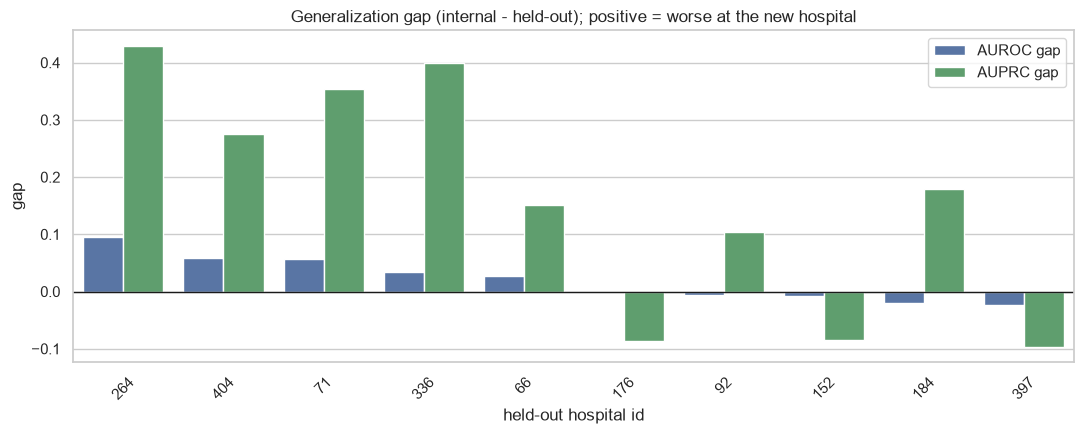

Largest AUROC gap: hospital 264 (0.095); mean gap = 0.021, sd = 0.039


In [30]:
# define and plot the generalization gap using seaborn. 
order_gap = ext.sort_values('gap_auroc', ascending=False)['hospital'].tolist()   # biggest gap first
gap_long = ext.melt(id_vars='hospital', value_vars=['gap_auroc', 'gap_auprc'], var_name='metric', value_name='gap')
gap_long['metric'] = gap_long['metric'].map({'gap_auroc': 'AUROC gap', 'gap_auprc': 'AUPRC gap'})

# FIGURE 2: generalization gap by held-out hospital
plt.figure(figsize=(11, 4.5))
sns.barplot(data=gap_long, x='hospital', y='gap', hue='metric', order=order_gap, palette=['#4C72B0', '#55A868'])
plt.axhline(0, color='k', lw=1)
plt.title('Generalization gap (internal - held-out); positive = worse at the new hospital')
plt.xlabel('held-out hospital id'); plt.ylabel('gap'); plt.xticks(rotation=45)
plt.legend(title='')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig2_generalization_gap.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"Largest AUROC gap: hospital {order_gap[0]} ({ext.set_index('hospital').loc[order_gap[0], 'gap_auroc']:.3f}); "
      f"mean gap = {ext.gap_auroc.mean():.3f}, sd = {ext.gap_auroc.std():.3f}")

Note that if for the specific split you chose, the gap is 0, then 1) this is great!, and 2) any research into reducing the gap is not applicable. 
You can try different splits / Y / X  to see if you can find a split that has a non-zero gap.

## Step 8: Explore causes of gaps 
Once we have a X / Y / split setting where there is a large gap, can we ask: Why might some hospitals have larger gaps? Why might some splits induce larger gaps? 
Could this be from: 
1. Which features X we choose?
2. Differences in missingness between training and heldout? 
3. Differences in outcome Y prevalence? 
4. Differences in hospital characteristics?
5. .... other? 
You don't need to find an answer, there is likely no single cause, but exploring this is a good exercise. 

Bonus question: What role do we think the ML model itself has in generalization gaps??

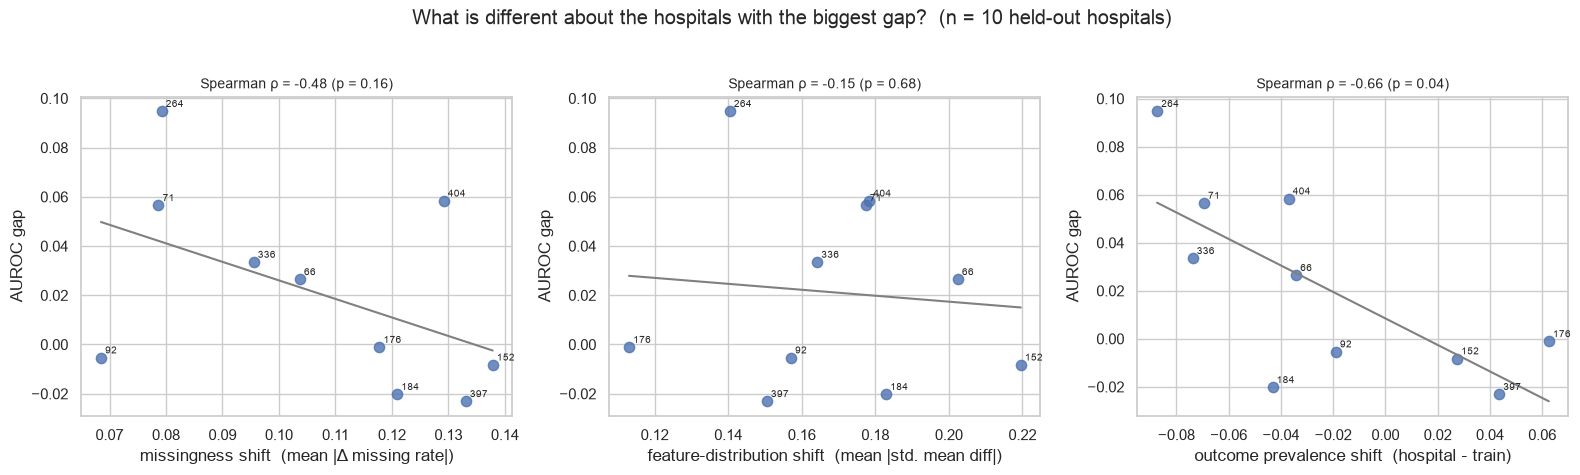

In [33]:
# For every held-out hospital: how different is it from the training hospitals?
#   miss_shift = mean |missing-rate(hospital) - missing-rate(train)| over numeric features
#   smd_shift  = mean |standardized mean difference| over numeric features  (feature-distribution shift)
#   prev_shift = hospital prevalence - training prevalence
tr_miss = train_inner[X_num_kept].isna().mean()
tr_mean = train_inner[X_num_kept].mean()
tr_std  = train_inner[X_num_kept].std().replace(0, np.nan)

rows, per_feature = [], {}
for h in ext['hospitalid']:
    d = heldout_df[heldout_df['hospitalid'] == h][X_num_kept]
    miss_diff = (d.isna().mean() - tr_miss)
    smd = (d.mean() - tr_mean) / tr_std
    per_feature[h] = pd.DataFrame({'miss_diff': miss_diff, 'smd': smd})
    hosp_prev = heldout_df.loc[heldout_df['hospitalid'] == h, OUTCOME_COL].mean()
    rows.append(dict(hospitalid=h, miss_shift=miss_diff.abs().mean(), smd_shift=smd.abs().mean(),
                     prev_shift=hosp_prev - ytr.mean()))
shift = pd.DataFrame(rows)
diag = ext.merge(shift, on='hospitalid')

# FIGURE 3: does the gap line up with how different the hospital is?
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
panels = [('miss_shift', 'missingness shift  (mean |Δ missing rate|)'),
          ('smd_shift',  'feature-distribution shift  (mean |std. mean diff|)'),
          ('prev_shift', 'outcome prevalence shift  (hospital - train)')]
for ax, (col, label) in zip(axes, panels):
    sns.regplot(data=diag, x=col, y='gap_auroc', ax=ax, ci=None, scatter_kws=dict(s=55), line_kws=dict(color='gray', lw=1.5))
    rho, pval = spearmanr(diag[col], diag['gap_auroc'])
    ax.set_title(f'Spearman ρ = {rho:.2f} (p = {pval:.2f})', fontsize=10)
    ax.set_xlabel(label); ax.set_ylabel('AUROC gap')
    for _, r in diag.iterrows():
        ax.annotate(r['hospital'], (r[col], r['gap_auroc']), fontsize=7, xytext=(3, 3), textcoords='offset points')
plt.suptitle(f'What is different about the hospitals with the biggest gap?  (n = {len(diag)} held-out hospitals)', y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig3_gap_vs_shift_diagnostics.png', dpi=200, bbox_inches='tight')
plt.show()

#Right panel: the dots slope down. Hospitals where this diagnosis is rarer than usual have the worst results. This is the only real clue.
#Left and middle panels: no clear pattern, so missing data and differences in the numbers don’t explain much.

In [32]:
# Which FEATURES are risky? Features the model relies on heavily AND that look different at the worst hospital.
worst = ext.sort_values('gap_auroc', ascending=False).iloc[0]['hospitalid']
print("Worst held-out hospital:", worst)

coefs = pd.Series(model.named_steps['lr'].coef_[0], index=model.named_steps['prep'].get_feature_names_out())
coefs = coefs[coefs.index.str.startswith('num__')]
coefs.index = coefs.index.str.replace('num__', '', regex=False)

risk = (pd.DataFrame({'abs_coef': coefs.abs()})
        .join(per_feature[worst])
        .assign(abs_miss_diff=lambda t: t.miss_diff.abs(), abs_smd=lambda t: t.smd.abs()))
risk['risk_score'] = risk['abs_coef'] * (risk['abs_miss_diff'] + risk['abs_smd'])   # simple heuristic, not a theorem
risk.sort_values('risk_score', ascending=False).head(15).round(3)

Worst held-out hospital: 264


,abs_coef,miss_diff,smd,abs_miss_diff,abs_smd,risk_score
anion gap,0.259,-0.229,1.449,0.229,1.449,0.434
noninvasivemean_bin1,0.510,-0.040,-0.130,0.040,0.130,0.087
ionized calcium,0.073,-0.456,0.648,0.456,0.648,0.081
chloride,0.230,-0.017,-0.314,0.017,0.314,0.076
MPV,0.043,-0.329,0.545,0.329,0.545,0.038
noninvasivediastolic_bin1,0.371,-0.041,0.060,0.041,0.060,0.037
noninvasivemean_bin2,0.120,-0.078,-0.169,0.078,0.169,0.030
TV,0.292,0.086,-0.009,0.086,0.009,0.028
polys,0.086,-0.187,0.104,0.187,0.104,0.025
sao2_bin2,0.105,-0.064,-0.167,0.064,0.167,0.024


**Your interpretation goes here.** Things to comment on after you run this on your data:
- Is the gap large or small overall (Figure 2)? Are a few hospitals clearly worse than the rest, or is it mostly noise from small samples (check `n` and `n_pos` in the table)?
- In Figure 3, does the gap track missingness shift, feature-distribution shift, or prevalence shift? With only ~10 held-out hospitals the correlations are weak evidence, so say so.
- In the last table, are the "risky" features (high weight in the model, very different at the worst hospital) things you could have flagged **without** seeing that hospital, using only the training hospitals? That is the question Project 2 is built on.
- Try another split (`CHOSEN_SPLIT = 'region=...'`) or another outcome and see whether the story changes.


Size of the gap: small. Compared fairly, the held-out AUROC averages about 0.855 against 0.837 internally. Only hospital 264 is clearly lower. The small hospitals with 16 to 18 cases are mostly noise.
What explains it: Hospitals where the diagnosis is rarer than in training had bigger gaps. With 10 hospitals and one far-off point (264), this is weak evidence.
Other outcome: the story changed. With mortality there was no gap and nothing explained it. With respiratory failure (label_J96.00) there’s one weak hospital and a prevalence lead. Other splits for this outcome haven’t been run yet.

**Bonus: role of the model itself.** A flexible model (e.g. XGBoost) can latch onto subtle hospital-specific patterns, such as which labs a hospital tends to order, which look predictive in training but do not transfer. A heavily regularized linear model is less able to do that, but may also leave signal on the table. Comparing the gaps of the two would be a natural experiment.

In [26]:
 def run_split(heldout_ids, train_ids=None, C=0.1):
    heldout_ids = list(heldout_ids)
    held = patient_agg['hospitalid'].isin(heldout_ids)
    tr_mask = ~held if train_ids is None else patient_agg['hospitalid'].isin(list(train_ids))
    assert not (held & tr_mask).any(), "a hospital is in both train and held-out!"
    tr_all, ho = patient_agg[tr_mask].copy(), patient_agg[held].copy()

    tr, va = train_test_split(tr_all, test_size=0.2, random_state=SEED, stratify=tr_all[OUTCOME_COL])
    tr, va = tr.copy(), va.copy()
    for d in (tr, va, ho):
        d[X_cat] = d[X_cat].astype(object).fillna('Missing')

    keep = [c for c in X_num if tr[c].isna().mean() <= MAX_MISSING]
    imp = SimpleImputer(strategy='median', add_indicator=True).fit(tr[keep])      # fit on train only
    names = imp.get_feature_names_out().tolist()
    def frame(d):
        num = pd.DataFrame(imp.transform(d[keep]), columns=names, index=d.index)
        return pd.concat([num, d[X_bin].fillna(0), d[X_cat]], axis=1)
    Xtr, Xva, Xho = frame(tr), frame(va), frame(ho)

    ind = [c for c in names if c.startswith('missingindicator_')]
    scaled = [c for c in names if c not in ind]
    prep = ColumnTransformer([('num', StandardScaler(), scaled),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), X_cat),
                              ('pass', 'passthrough', ind + X_bin)], remainder='drop')
    m = Pipeline([('prep', prep), ('lr', LogisticRegression(C=C, max_iter=2000))]).fit(Xtr, tr[OUTCOME_COL])

    int_auroc = roc_auc_score(va[OUTCOME_COL], m.predict_proba(Xva)[:, 1])
    p_ho, y_ho = m.predict_proba(Xho)[:, 1], ho[OUTCOME_COL].to_numpy()
    rows = []
    for h in sorted(ho['hospitalid'].unique()):
        k = (ho['hospitalid'] == h).to_numpy()
        rows.append(dict(hospitalid=h, n=int(k.sum()), n_pos=int(y_ho[k].sum()), auroc=roc_auc_score(y_ho[k], p_ho[k])))
    out = pd.DataFrame(rows)
    out['gap_auroc'] = int_auroc - out['auroc']
    return dict(n_train=len(tr_all), int_auroc=int_auroc, per_hospital=out)

In [27]:
MAX_HELD = 9                                   # the task says fewer than 10 held-out hospitals
rng = np.random.default_rng(SEED)
cands = {}                                     # name -> (heldout_ids, train_ids or None)

for col in ['hospital_numbedscategory', 'hospital_region']:
    for val, grp in eligible.groupby(col):     # hold out eligible hospitals with this bed size / region
        ids = grp.index.to_numpy()
        if len(ids) >= 5:
            cands[f'hold out {col}={val}'] = (rng.choice(ids, min(MAX_HELD, len(ids)), replace=False), None)

for val in hosp_stats['hospital_region'].dropna().unique():      # train ONLY on one region, test on others
    train_ids = hosp_stats.index[hosp_stats['hospital_region'] == val].to_numpy()
    test_pool = eligible.index[eligible['hospital_region'] != val].to_numpy()
    if hosp_stats.loc[train_ids, 'n_patients'].sum() > 10_000 and len(test_pool) >= 5:
        cands[f'train only {val}'] = (rng.choice(test_pool, MAX_HELD, replace=False), train_ids)

print(len(cands), "candidate splits")

results, details = [], {}
for name, (held_ids, train_ids) in cands.items():
    r = run_split(held_ids, train_ids)
    ph = r['per_hospital']
    details[name] = r
    results.append(dict(split=name, n_train=r['n_train'], n_heldout_hosp=len(ph), internal_auroc=r['int_auroc'],
                        mean_gap=ph.gap_auroc.mean(), max_gap=ph.gap_auroc.max(),
                        n_hosp_gap_gt_0_05=int((ph.gap_auroc > 0.05).sum())))
    print(f"{name:45s} mean gap = {ph.gap_auroc.mean():+.3f}   max gap = {ph.gap_auroc.max():+.3f}")

gap_search = pd.DataFrame(results).sort_values('mean_gap', ascending=False).reset_index(drop=True)
gap_search.round(3)

11 candidate splits
hold out hospital_numbedscategory=100 - 249   mean gap = +0.033   max gap = +0.109
hold out hospital_numbedscategory=250 - 499   mean gap = +0.050   max gap = +0.155
hold out hospital_numbedscategory=<100        mean gap = +0.024   max gap = +0.063
hold out hospital_numbedscategory=>= 500      mean gap = +0.034   max gap = +0.093
hold out hospital_region=Midwest              mean gap = +0.032   max gap = +0.091
hold out hospital_region=Northeast            mean gap = +0.042   max gap = +0.100
hold out hospital_region=South                mean gap = +0.016   max gap = +0.042
hold out hospital_region=West                 mean gap = +0.020   max gap = +0.107
train only Midwest                            mean gap = +0.073   max gap = +0.202
train only South                              mean gap = +0.066   max gap = +0.137
train only West                               mean gap = +0.059   max gap = +0.129


,split,n_train,n_heldout_hosp,internal_auroc,mean_gap,max_gap,n_hosp_gap_gt_0_05
0,train only Midwest,47108,9,0.873,0.073,0.202,5
1,train only South,43048,9,0.873,0.066,0.137,5
2,train only West,27161,9,0.882,0.059,0.129,4
3,hold out hospital_numbedscategory=250 - 499,127254,9,0.889,0.050,0.155,3
4,hold out hospital_region=Northeast,127352,8,0.874,0.042,0.100,3
5,hold out hospital_numbedscategory=>= 500,117589,9,0.882,0.034,0.093,2
6,hold out hospital_numbedscategory=100 - 249,129125,9,0.881,0.033,0.109,3
7,hold out hospital_region=Midwest,125870,9,0.880,0.032,0.091,3
8,hold out hospital_numbedscategory=<100,133335,7,0.878,0.024,0.063,3
9,hold out hospital_region=West,127221,9,0.877,0.020,0.107,2
